# Exploratory Data Analysis

In this notebook the data is viewed, cleaned, and formatted.

There was found to be no null values and multiple duplicate rows were removed. Using RegEx the format of the job titles was simplified. Then a column was created containing stemmed versions of the job titles.

A similarity score was manually given to each candidate - 5 meaning highest similarity and 1 meaning lowest similarity.

The most frequent words were displayed in a word cloud.

This updated dataset was saved as a new CSV file.

In [31]:
# import the necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from nltk.stem import PorterStemmer
import re

In [32]:
# remove limit of column display width so full job titles can be viewed
pd.set_option('display.max_colwidth', None)

In [33]:
# import data from CSV file
data = pd.read_csv("../data/potential_talents_raw.csv")

In [34]:
# view the first few data rows
data.head()

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Program in Korea),Kanada,500+,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500+,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN


In [35]:
# check for null values
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          104 non-null    int64  
 1   job_title   104 non-null    object 
 2   location    104 non-null    object 
 3   connection  104 non-null    object 
 4   fit         0 non-null      float64
dtypes: float64(1), int64(1), object(3)
memory usage: 4.2+ KB


In [36]:
# number of unique job titles in the data
data['job_title'].nunique()

52

In [37]:
# number of times each job title occurs
data['job_title'].value_counts()

job_title
2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional                 7
Aspiring Human Resources Professional                                                                                    7
Student at Humber College and Aspiring Human Resources Generalist                                                        7
People Development Coordinator at Ryan                                                                                   6
Native English Teacher at EPIK (English Program in Korea)                                                                5
Aspiring Human Resources Specialist                                                                                      5
HR Senior Specialist                                                                                                     5
Student at Chapman University                                                                                            4
SVP, C

In [38]:
# number of identical rows
data.duplicated(subset=['job_title', 'location', 'connection']).sum()

np.int64(51)

In [39]:
# display identical rows
data[data.duplicated(subset=['job_title', 'location', 'connection'])].sort_values(by='job_title')

,id,job_title,location,connection,fit
56,57,2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,"Houston, Texas",85,NaN
13,14,2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,"Houston, Texas",85,NaN
14,15,2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,"Houston, Texas",85,NaN
30,31,2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,"Houston, Texas",85,NaN
43,44,2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,"Houston, Texas",85,NaN
18,19,2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,"Houston, Texas",85,NaN
34,35,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
47,48,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
22,23,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
28,29,Aspiring Human Resources Management student seeking an internship,"Houston, Texas Area",500+,NaN


In [46]:
# removing rows that are identical (other than in the id column)
data = data.drop_duplicates(subset=data.columns.difference(['id'])).reset_index(drop=True)

In [41]:
# converting the job titles to lower case, no punctuation, no excess white space, no returns
data['job_title'] = data['job_title'].str.replace(r'[\r\n]+', ' ', regex=True).str.replace(r'[^\w\s]', ' ', regex=True).str.lower().str.strip()

# replacing 'human recources' with 'hr'
data['job_title'] = data['job_title'].str.replace('human resources', 'hr')

# stemming
stemmer = PorterStemmer()
def stem_text(text):
    return ' '.join(
        stemmer.stem(word)
        for word in text.split()
    )

data['job_title_stem'] = data['job_title'].apply(stem_text)

In [42]:
# viewing first few rows of formatted and stemmed data
data.head(10)

,id,job_title,location,connection,fit,job_title_stem
0,1,2019 c t bauer college of business graduate magna cum laude and aspiring hr professional,"Houston, Texas",85,NaN,2019 c t bauer colleg of busi graduat magna cum laud and aspir hr profession
1,2,native english teacher at epik english program in korea,Kanada,500+,NaN,nativ english teacher at epik english program in korea
2,3,aspiring hr professional,"Raleigh-Durham, North Carolina Area",44,NaN,aspir hr profession
3,4,people development coordinator at ryan,"Denton, Texas",500+,NaN,peopl develop coordin at ryan
4,5,advisory board member at celal bayar university,"İzmir, Türkiye",500+,NaN,advisori board member at celal bayar univers
5,6,aspiring hr specialist,Greater New York City Area,1,NaN,aspir hr specialist
6,7,student at humber college and aspiring hr generalist,Kanada,61,NaN,student at humber colleg and aspir hr generalist
7,8,hr senior specialist,San Francisco Bay Area,500+,NaN,hr senior specialist
8,10,seeking hr hris and generalist positions,Greater Philadelphia Area,500+,NaN,seek hr hri and generalist posit
9,11,student at chapman university,"Lake Forest, California",2,NaN,student at chapman univers


In [43]:
# giving each job title a manual score: 1 = very bad match, 5 = very good match (mapped as id:score)
data['manual_score'] = None

manual_scores = {
    1:5,
    2:1,
    3:5,
    4:3,
    5:1,
    6:5,
    7:5,
    8:4,
    10:5,
    11:1,
    12:3,
    13:4,
    27:5,
    28:5,
    66:5,
    67:4,
    68:4,
    69:4,
    70:5,
    71:4,
    72:5,
    73:5,
    74:4,
    75:5,
    76:5,
    77:3,
    78:4,
    79:5,
    80:1,
    81:4,
    82:5,
    83:4,
    84:4,
    85:1,
    86:1,
    87:1,
    88:5,
    89:4,
    90:1,
    91:1,
    92:2,
    93:2,
    94:5,
    95:1,
    96:1,
    97:5,
    98:1,
    99:5,
    100:5,
    101:4,
    102:1,
    103:1,
    104:2
}

data['manual_score'] = data['id'].map(manual_scores)
data[['id', 'job_title', 'manual_score']].sort_values(by='manual_score', ascending=False).reset_index(drop=True)

,id,job_title,manual_score
0,1,2019 c t bauer college of business graduate magna cum laude and aspiring hr professional,5
1,79,liberal arts major aspiring hr analyst,5
2,75,nortia staffing is seeking hr payroll administrative professionals 408 709 2621,5
3,73,aspiring hr manager seeking internship in hr,5
4,72,business management major and aspiring hr manager,5
5,82,aspiring hr professional an energetic and team focused leader,5
6,70,retired army national guard recruiter office manager seeking a position in hr,5
7,88,hr management major,5
8,66,experienced retail manager and aspiring hr professional,5
9,28,seeking hr opportunities,5


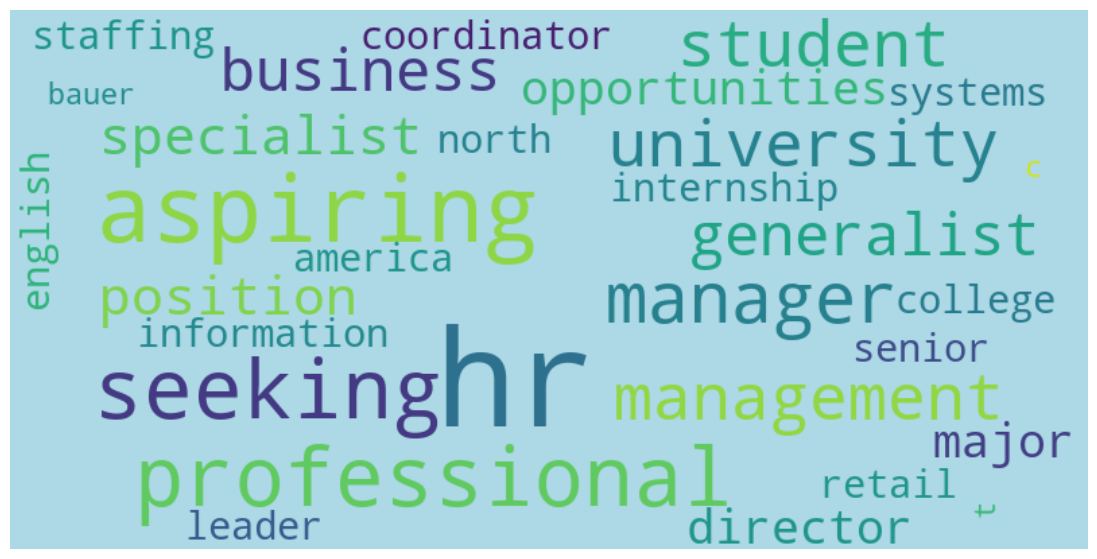

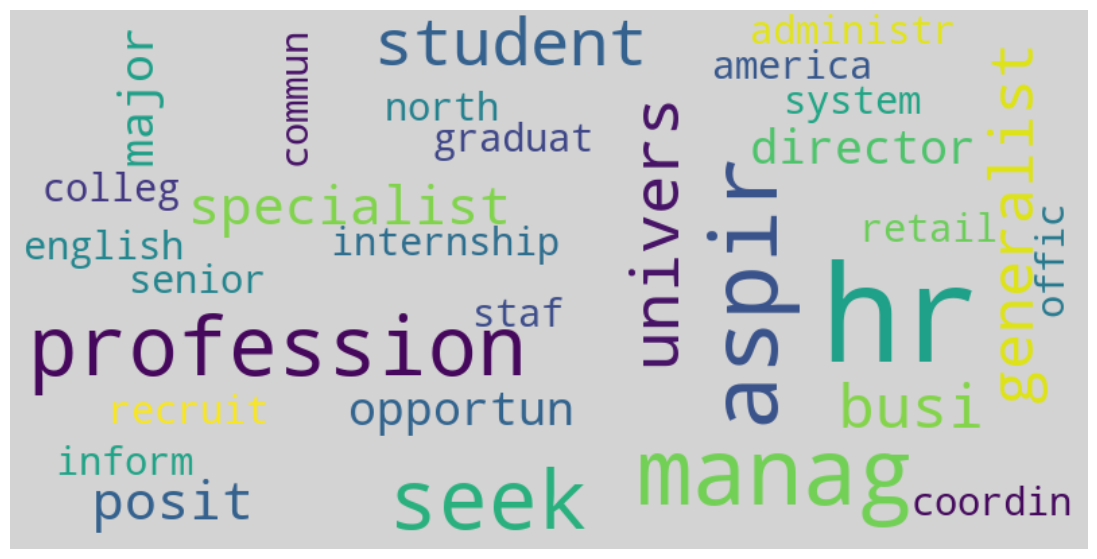

In [44]:
# creating a word cloud

# turning all job titles into a single string
text = " ".join(data['job_title'].astype(str))

# creating word cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='lightblue',
    max_words=30,
    max_font_size=100,
    colormap='viridis',
    collocations=False
).generate(text)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

# creating identical word cloud for stemmer job titles
# turning all job titles into a single string
text = " ".join(data['job_title_stem'].astype(str))

# creating word cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='lightgray',
    max_words=30,
    max_font_size=100,
    colormap='viridis',
    collocations=False
).generate(text)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [45]:
# saving cleaned data to be used in other notebooks
data.to_csv("../data/potential_talents_cleaned.csv", index=False)